# Project 1: Exploring USA County Health Rankings and Roadmaps

Names: Nicole Teerman

Student IDs: 604890

Collaborators: n/a


## Instructions

This homework is an _open-ended midterm project_ for our class. 

We will be using the techniques and approaches introduced in the first half of the semester, focussing on M0, M1, M2, and M6 mostly. 

> **Note:** You may do some supervised learning (as covered in M3 and M5), however, this should not be the _only_ thing(s) you do. We definitley want to see DS workflow/life-cycle (**M1**), lots of EDA (**M2**), custering(**M4**) and a discussion of ethical issues (**M6**):

* **[M0] Python for DS**
* **[M1] The DS and ML Workflows**
* [M2] Linear Regression (if applicable - depends on problem/dataset)
* **[M3] Exploratory Data Analsyis**
* **[M4] Clustering**
* [M5] Sentiment Analysis (if applicable - depends on problem/dataset)
* [M6] Linear Classification (if applicable - depends on problem/dataset)
* **[M7] Ethical Thinking for DS**

The main focus of this project is on the first three modules [M0]-[M2], as well as the ethical consderations for DS from [M7]. In particular, it will be helpful to review **Lab 3 & hw 3(Analyzing the MoMA Data)** first. Most of the things you will do in this midterm project are explained in `Lab3` and `hw3`. Then, review the other labs and hws to recap the  general workflow of our DS approaches to the various problems we have worked on so far. This will help you to be prepared for all the steps in this project, so that you do not miss anything. 

In gernal, you should feel free to import any package that we have previously used in class; you might want to also experiemnt with or use other packages. Ensure that all plots have the necessary components that a plot should have (e.g. axes labels, a title, a legend). 

> **!! Do not use any packages/ML models that we did not discuss in this class (yet)!!**

Additionally, note that this assignment is more like a project than a typical homework and it will have a slightly different structure than the hws in the past. One of the reasons why Jupyter Notebooks are so popular in the field is because you can really treat them like notebooks to explain your findings as you discover them. In this assignment, we provide some **Problem** stubs following the EDA/DS workflow and you will need to fill in the analysis and structure as you go.

Furthermore, in addition to recording your collaborators on this homework, please also remember to cite/indicate all external sources used when finishing this assignment. This includes peers, TAs, and links to online sources. 

Frequently **save** your notebook!

### Learning Goals
* **[G1-6]** Analyze and visualize continuous features.
* **[G3-7]** Analyze and visualize categorical features.
* **[G3-5]** Analyze and visualize both continuous and categorical variables, specifically: the distribution of individual variables, the relationship (or correlation) between different variables, and the comparison of different variables
* **[G3-6]** Perform the EDA Process (data exploration, understanding, and visualization)
* **[G3-8]** Formulate and answer data questions.
* **[G3-9]** Compute common summary statistics from data using pandas.
* **[G4-6]** Implement the k-means algorithm from scratch and by using scikit-learn.
* **[G4-8]** Visually evaluate k-means clustering results for 2d data.
* **[G4-10]** Interpret the clusters created by a clustering approach.
* **[G7-4]** Recognize different types and sources of biases that give rise to ethical issues in the data science workflow.
* **[G7-10]** Discuss real-world examples of ethical issues when performing data science with your peers.
* **[G7-11]** Realize that when using data we face  multi-faceted and multi-layered challenges.
* **[Lab-G5]** Contribute the use of a specific (new-to-you) built-in Python function to the project solution after reading its documentation. Be ready to explain its functionality.
* **[Optional]** Collaborate with a partner (teamwork and team communication) on an open ended data science project.

### Collaborators and Sources
Furthermore, in addition to recording your **collaborators** on this homework, please also remember to **cite/indicate all external sources** used when finishing this assignment. 
> This includes peers, TAs, and links to online sources. 

Note that these citations will not free you from your obligation to submit your _own_ code and write-ups, however, they will be taken into account during the grading and regrading process.

In [53]:
# collaborators and sources:
# Albert Einstein and Marie Curie
# https://developers.google.com/edu/python/strings

# your code here
answer = 'my answer'

**citation for the women's health data:** 
Frost, J. J., Frohwirth, L. F., Blades, N., Zolna, M. R., Douglas-Hall, A., & Bearak, J. (2017). *Publicly funded contraceptive services at U.S. clinics, 2015*. Guttmacher Institute. https://www.guttmacher.org/report/publicly-funded-contraceptive-services-us-clinics-2015

https://www.guttmacher.org/sites/default/files/report_downloads/fpcliniccensus2015-state-county-data.xlsx?utm_source=chatgpt.com

### Submission instructions
* Submit this Python notebook, including your answers in the code cells as homework submission.
* **Feel free to add as many cells as you need to** — just make sure you don't change what we gave you. 
* **Does it spark joy?** Note that you will be partially graded on the presentation (_cleanliness, clarity, comments_) of your notebook so make sure you [Marie Kondo](https://lifehacker.com/marie-kondo-is-not-a-verb-1833373654) your notebook before submitting it.

## 1. Introduction

We are using the 2024 County Health Release National Data compiled and curated by the County Health Rankings & Roadmaps (CHR&R), a program of the University of Wisconsin Population Health Institute. It provides data at the county-level to enable analysis of the reasons for the differences in health within each community and across communities. (https://www.countyhealthrankings.org/).

For our midterm project this semester, the data (analytic_data2024.csv) and the data dictionary is already stored in this box folder (https://wustl.box.com/s/6sobk3ae12bup7ccp29y964q1pyuu0l7) for your convinence or you can also download it from https://www.countyhealthrankings.org/health-data/methodology-and-sources/data-documentation (2024 CHR CSV Analytic Data)

Our goal will be to use the clean dataset (analytic_data2024.csv) to gain some insight about US County Health Rankings & Roadmaps (CHR&R) characteristics and (_hopefully_) find some patterns in this data.

In general, we will be following the EDA process:
1. Get the data and gain **basic understanding**
2. **Wrangle** the data
3. **Profile** the data
4. Develop questions to investigate (form a **hypotheses**)
5. Use the data to **investigate** hypothesis
6. **Summarize** results and answer questions 
7. **Critically review** our workflow and discuss ethical concerns

In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("utility/data/analytic_data2024.csv", low_memory=False)

print("rows and columns:", df.shape)
display(df.head())
display(df.info())
display(df.describe(include="all"))

rows and columns: (3196, 770)


,State FIPS Code,County FIPS Code,5-digit FIPS Code,State Abbreviation,Name,Release Year,County Clustered (Yes=1/No=0),Premature Death raw value,Premature Death numerator,Premature Death denominator,...,% Female raw value,% Female numerator,% Female denominator,% Female CI low,% Female CI high,% Rural raw value,% Rural numerator,% Rural denominator,% Rural CI low,% Rural CI high
0,statecode,countycode,fipscode,state,county,year,county_clustered,v001_rawvalue,v001_numerator,v001_denominator,...,v057_rawvalue,v057_numerator,v057_denominator,v057_cilow,v057_cihigh,v058_rawvalue,v058_numerator,v058_denominator,v058_cilow,v058_cihigh
1,00,000,00000,US,United States,2024,NaN,7971.5097891,4535347,921750763,...,0.504081237,168004004,333287557,NaN,NaN,0.2000313707,66300254,331449281,NaN,NaN
2,01,000,01000,AL,Alabama,2024,NaN,11415.734833,98140,13812804,...,0.5137532379,2606936,5074296,NaN,NaN,0.4226276049,2123399,5024279,NaN,NaN
3,01,001,01001,AL,Autauga County,2024,1,9407.9484384,942,159452,...,0.5129603909,30654,59759,NaN,NaN,0.406768132,23920,58805,NaN,NaN
4,01,003,01003,AL,Baldwin County,2024,1,8981.5753533,3789,633571,...,0.5123906913,126271,246435,NaN,NaN,0.3758645536,87113,231767,NaN,NaN


<class 'pandas.DataFrame'>
RangeIndex: 3196 entries, 0 to 3195
Columns: 770 entries, State FIPS Code to % Rural CI high
dtypes: str(770)
memory usage: 18.8 MB


None

,State FIPS Code,County FIPS Code,5-digit FIPS Code,State Abbreviation,Name,Release Year,County Clustered (Yes=1/No=0),Premature Death raw value,Premature Death numerator,Premature Death denominator,...,% Female raw value,% Female numerator,% Female denominator,% Female CI low,% Female CI high,% Rural raw value,% Rural numerator,% Rural denominator,% Rural CI low,% Rural CI high
count,3196,3196,3196,3196,3196,3196,3144,3141,3141,3141,...,3196,3196,3196,1,1,3196,3196,3196,1,1
unique,53,327,3196,53,1930,2,3,3140,1648,3115,...,3193,3090,3131,1,1,2067,3071,3137,1,1
top,48,000,fipscode,TX,Washington County,2024,1,8975.9560193,130,33779,...,0.5241432384,4078,3217,v057_cilow,v057_cihigh,1,0,45014,v058_cilow,v058_cihigh
freq,255,52,1,255,30,3195,3088,2,10,2,...,2,3,3,1,1,1105,26,2,1,1


## 2. Getting Familiar with the Data

In this section, we will get a feel for our data and tidy it up so that we can analyize it later. 
Download the data from the source/link given above and be sure to save the data in a folder called `data` under the `utility` directory. Your final path should look like `utility/data/analytic_data2024.csv` -- if it doesn't **we will not be able to properly grade your assignment!**



### Problem 1

Let's start by taking a look at our data and the README that includes essential information for the data. 

**Write-up!** Describe the data, answering questions including, but not limited to, these: Where does the data come from? How was it obtained? How many examples (rows) and features (columns) does the dataset have? What kinds of features are in the dataset -- numerical  (discrete/continuous) or categorical(ordinal/nominal)? What range of values does each feature  take? List five or more features you find the most relevant and would like to explore further. 
> **Hint**: Consider the steps of EDA; what would you like to know about this dataset. 

**Answer here:** 

The data comes from the 2024 County Health Rankings and Roadmaps (CHR&R) program which collects health-related data from multiple sources to evaluate health outcomes and influential factors across US counties. The data was obtained from the 2024 CHR CSV Analytic Data file from the County Health Rankings and Roadmaps website.

The original dataset contains 3195 rows and 770 columns. Each row represents a geographic observation (US counties primarily with some state / national summary records as well) and the columns represent different health measures, demographic characteristics, socioeconomic conditions, and indicators of healthcare access.

The data contains both numerical and categorical features. Continuous numerical features: percentages, rates, averages. Examples include the percentage of uninsured residents, poverty rates, and the number of heatlhcare providers per population. Numerical features (discrete): Counts of individuals, healthcare providers, or health-related events (typically non-negative as well). Nominal categorical features: state names, county names, and geographic identifiers. Ordinal categorical features: ranked / ordered health measures that indicate relative performance.

Different features have varying ranges, such as how percentages range from 0-100 while geographic identifiers represent specific locations rather than quantities.

The features I'm most interested in exploring are: 1) uninsured adults (percentage), 2) primary care physician availability relative to the population, 3) median household income (how socioeconomic conditions may influence access to medical care / services), 4) poor physical health days (average number of physically unhealthy days reported), and 5) children in poverty (percentage).

#### Required: Commit your code
If working in a team we want to see commits from both team member's Github accounts over the duration of the project. Not every team ember needs to commit something ofr every problem, however make sure your commit history reflects an equal work distribution amnonmg both team members. Use a _verbose commit message_ describing your contribution for all your commits.  

<div class="alert-success">
<b>Commit your Code <i>now</i>!</b>
<br> Commit your progress to the (remote) lab repo and have a team member (who is not currently sharing the screen) check and confirm that it is there! Use a descriptive commit message, such as: "<i>descriptive commit message</i>"  
</div>

### Problem 2

Data cleaning and processing: Let's do some data wrangling. 

**Write up!** Considering your description of the dataset from [Problem 1](#Problem-1), how should we clean this data?

Here are some initial instructions to get you started and feel free to do further cleaning if it makes sense for your data analytics:
- Retain only the following columns: 'State FIPS Code', 'County FIPS Code', '5-digit FIPS Code', 'Name', 'State Abbreviation', 'Release Year' and all the '*_raw value'. Report any changes in data size or shape after each update or reduction.
> **Hint** You can use the `endswith()` function or regex to get the column names that end with a specific suffix.
- Remove the rows corresponding to the aggregate values for the entire US and one for each state and District of Columbia. **These rows have a “County FIPS Code” value of “000”.**
- Remove columns where over 10% of the values are missing values. This should bring the number of columns down to ~75.
> **Hint** Use the `df.dropna(axis=1, thresh=n)` method, where n is the minimum number of non-missing values a column must have to be retained. Given that a column should have at least 90% of its values present, how would you determine `n`?

- Keep only complete rows, i.e., remove rows with any missing value.
- Feel free to rename the columns, making them more meaningful.
- Drop the first row of the dataset.
- Covert the '*_raw value' columns to a numeric data type.
> **Hint** Use `lambda` and `pd.to_numeric`
- Based on the goals of your project, feel free to get rid of more features to keep your dataset more aligned with your project goals and further analysis.

**Do this!** In the cells below, **explain** and perform the steps that you need to prepare this data for further analysis. Make sure that your implementations and write-ups (for processing and analysis) are presented well and effectively describe your workflow. You should add comments and markdown cells for your documentation as you see fit!  


*Grading Note: Your work will be graded for _readability_, _style_, and _cleanlines_. So, carefully document your code and use descriptive/intuitive variable names. For write-ups use consice and clear language like in a written project report.*

> **Hint**: You can use our previous labs as examples of how you might do this. 
Also, you might want to come back to this step later on, since you might encounter problems with the data once you actually analyze it. Remember, you may add as many cells (for code and text) as you need below. Here — we gave you one for free!

**Answer:** To prepare the rankings data set for analysis, I need to clean the data by removing unncessary columns, aggregate observations, and missing values while ensuring that the remaining variables are kept in appropriate data types. The unncessary information would exclude, as listed above, 'State FIPS Code', 'County FIPS Code', '5-digit FIPS Code', 'Name', 'State Abbreviation', 'Release Year' and all the '*_raw value'.

Next, I'll remove the national and state-level observations since I only want to focus on comparisons between US counties. Then, I will remove columns where more than 10% observations are missing, ensuring that remaining features have sufficient data for analysis. With this, I'll remove any rows containing missing values to create a complete dataset.

I will then examine the cleaned data set and its dimensions + data types to verify that my process was successful. I'll remove the first remaining row (as instructed) and convert the raw value columns into numerical data types for when I use them for statistical analysis and visualizations.

In [55]:
import pandas as pd

# original data set!
clean_df = df.copy()
print("original:", clean_df.shape)

# identifying columns and raw values
columns = ['State FIPS Code', 'County FIPS Code',
           '5-digit FIPS Code', 'Name',
           'State Abbreviation', 'Release Year']

raw_columns = [col for col in df.columns if col.endswith('raw value')]
clean_df = clean_df[columns + raw_columns]
print("after selecting columns:", clean_df.shape)

# removing national and state level content
clean_df = clean_df[clean_df['County FIPS Code'].astype(str).str.zfill(3) != '000']
print("after removing aggregate rows (national and state level content):", clean_df.shape)

# missing 10% data
clean_df = clean_df.dropna(axis=1, thresh=int(len(clean_df) * 0.9 + 0.999999))
print("after removing columns (missing >=10% data):", clean_df.shape)

# rows w missing values
clean_df = clean_df.dropna()
print("after removing rows (missing values):", clean_df.shape)

# dropping first row
clean_df = clean_df.iloc[1:]
print("after dropping the first row:", clean_df.shape)

# converting raw values to numerical values
raw_columns = [col for col in clean_df.columns if col.endswith('raw value')]
clean_df[raw_columns] = clean_df[raw_columns].apply(
    lambda x: pd.to_numeric(x, errors='coerce')
    # not sure how to use lambda, is this valid?
)

clean_df = clean_df.dropna()
print("final data set:", clean_df.shape)

# checking
display(clean_df.head())
print(clean_df.dtypes)

original: (3196, 770)
after selecting columns: (3196, 91)
after removing aggregate rows (national and state level content): (3144, 91)
after removing columns (missing >=10% data): (3144, 75)
after removing rows (missing values): (2450, 75)
after dropping the first row: (2449, 75)
final data set: (2449, 75)


,State FIPS Code,County FIPS Code,5-digit FIPS Code,Name,State Abbreviation,Release Year,Premature Death raw value,Poor or Fair Health raw value,Poor Physical Health Days raw value,Poor Mental Health Days raw value,...,% 65 and Older raw value,% Non-Hispanic Black raw value,% American Indian or Alaska Native raw value,% Asian raw value,% Native Hawaiian or Other Pacific Islander raw value,% Hispanic raw value,% Non-Hispanic White raw value,% Not Proficient in English raw value,% Female raw value,% Rural raw value
3,01,001,01001,Autauga County,AL,2024,9407.948438,0.173,3.910265,5.703204,...,0.164109,0.210111,0.004719,0.011781,0.001222,0.033819,0.720511,0.003665,0.512960,0.406768
4,01,003,01003,Baldwin County,AL,2024,8981.575353,0.152,3.730943,5.373666,...,0.219287,0.082249,0.008108,0.011561,0.000665,0.050362,0.829785,0.007867,0.512391,0.375865
5,01,005,01005,Barbour County,AL,2024,13138.848362,0.273,5.023488,6.014294,...,0.206225,0.471950,0.007245,0.004695,0.002793,0.051000,0.452724,0.019807,0.471222,0.659200
6,01,007,01007,Bibb County,AL,2024,12675.434581,0.220,4.552795,5.824583,...,0.178050,0.207362,0.005726,0.002908,0.001318,0.031766,0.739968,0.002892,0.464894,1.000000
7,01,009,01009,Blount County,AL,2024,11541.495069,0.186,4.246335,5.664851,...,0.190903,0.017274,0.006335,0.004352,0.001311,0.100702,0.859927,0.021952,0.502907,0.904894


State FIPS Code                              str
County FIPS Code                             str
5-digit FIPS Code                            str
Name                                         str
State Abbreviation                           str
                                          ...   
% Hispanic raw value                     float64
% Non-Hispanic White raw value           float64
% Not Proficient in English raw value    float64
% Female raw value                       float64
% Rural raw value                        float64
Length: 75, dtype: object


**aforementioned info** just wanted to include this for greater clarity:

original: (3196, 770);
after selecting columns: (3196, 91);
after removing aggregate rows (national and state level content): (3144, 91);
after removing columns (missing >=10% data): (3144, 75);
after removing rows (missing values): (2450, 75);
after dropping the first row: (2449, 75);
final data set: (2449, 75).

#### Required: Commit your code
If working in a team we want to see commits from both team member's Github accounts over the duration of the project. Not every team ember needs to commit something ofr every problem, however make sure your commit history reflects an equal work distribution amnonmg both team members. Use a _verbose commit message_ describing your contribution for all your commits.  

<div class="alert-success">
<b>Commit your Code <i>now</i>!</b>
<br> Commit your progress to the (remote) lab repo and have a team member (who is not currently sharing the screen) check and confirm that it is there! Use a descriptive commit message, such as: "<i>descriptive commit message</i>"  
</div>

### Problem 3

Formulating and Answering Questions Through Analysis and Visualizations 

**Do this!** Now that we cleaned up our data, we are ready to look into it. In this problem, we want to profile our data and explore its variables.

> **Hint**: Note that the way some data is stored does not necesarily mean that each column should correspond to a seperate variable. Feel free to define your own variables based on the input data. Looking at the dataset documentation (data dictionary) might be helpful to figure out meaningful representations. Also note that there are no right or wrong representations here (since it is your job to find something interesting in the data, it is also up to you to choose the data/variable representations). Again, you might want to iterate over this step again later after doing some more exploration. 

> **Hint**: Recall from Lab3, this step usually involves computing summary statistics and basic plots _where applicable_. Try plotting some of the data (with appropriate plots; remember the lecture content - some plots introduced in there ( we did not yet use in the lab or hw) could be useful). Then, highlight a few of the more interesting ones and discuss why you thought they were interesting — for both our sakes, **please only include the most interesting ones** in your actual submission!!  Again note that there are no right or wrong features to choose here (since it is your job to find something interesting in the data, it is also up to you to choose the data/variables to include). Just be sure to make a selection. You will not receive any credit by simply plotting everything!  

*Grading Note*: Your work will be graded for _creativity_ and _aesthetics_. Be creative in the plots you use and select visulatizations and colors that make for a plesant and intuitive viewing expereince. The goal of a good visualization is that the viewer will quickly understand your figures.* 

Once again, we have provided a _free_ cell for you to use; make as many as you need. Use text/markdown cells to describe what you are doing and what your findings are. 

> **Note on Committing your work:**
We encourage you to commit intermediate coding progress even _within a problem_. Always commit more frequently than you think! 

**stuff you probably want to read:** I want to explore the cleaned county health rankings dataset to better understand patterns in healthcare access and scoioeconomic conditions across US counties. I am particularly interested in how income, insurance coverage, and physician availability differ across counties since these factors influence access to medical care / services. For this, I will use summary statistics and visualizations to identify distributions and potential relationships to develop my research question about health disparities -- AND their possible implications for women's reproductive / sexual health care.

In [56]:
# finding columns related to my research interests
keywords = ['uninsured', 'income', 'primary care',
            'poverty', 'physical health']

for col in clean_df.columns:
    if any(word in col.lower() for word in keywords):
        print(col)

Poor Physical Health Days raw value
Uninsured raw value
Primary Care Physicians raw value
Children in Poverty raw value
Income Inequality raw value
Uninsured Adults raw value
Uninsured Children raw value
Other Primary Care Providers raw value
Median Household Income raw value


In [57]:
# summary statistics for the numerical variables!
display(clean_df.describe())

,Premature Death raw value,Poor or Fair Health raw value,Poor Physical Health Days raw value,Poor Mental Health Days raw value,Low Birthweight raw value,Adult Smoking raw value,Adult Obesity raw value,Food Environment Index raw value,Physical Inactivity raw value,Access to Exercise Opportunities raw value,...,% 65 and Older raw value,% Non-Hispanic Black raw value,% American Indian or Alaska Native raw value,% Asian raw value,% Native Hawaiian or Other Pacific Islander raw value,% Hispanic raw value,% Non-Hispanic White raw value,% Not Proficient in English raw value,% Female raw value,% Rural raw value
count,2449.000000,2449.000000,2449.000000,2449.000000,2449.000000,2449.000000,2449.000000,2449.000000,2449.000000,2449.000000,...,2449.000000,2449.000000,2449.000000,2449.000000,2449.000000,2449.000000,2449.000000,2449.000000,2449.000000,2449.000000
mean,9755.837525,0.176598,3.904665,5.254884,0.083387,0.190130,0.372898,7.634341,0.266131,0.641434,...,0.200022,0.090775,0.020931,0.016545,0.001431,0.103193,0.753160,0.015752,0.497135,0.581361
std,3144.731200,0.042352,0.612328,0.581752,0.019354,0.038907,0.043887,1.042014,0.050192,0.201152,...,0.045041,0.132906,0.060980,0.023795,0.002444,0.134365,0.188881,0.024072,0.018946,0.317313
min,2771.454704,0.084000,2.261790,3.185544,0.039821,0.070000,0.174000,2.600000,0.120000,0.000000,...,0.054428,0.001862,0.000785,0.000618,0.000000,0.007688,0.028404,0.000000,0.339380,0.000000
25%,7538.638939,0.144000,3.448015,4.863008,0.069767,0.164000,0.350000,7.000000,0.231000,0.510374,...,0.172226,0.009620,0.004302,0.005891,0.000461,0.029447,0.638448,0.003097,0.492028,0.322329
50%,9342.548708,0.169000,3.883594,5.268291,0.080628,0.188000,0.376000,7.700000,0.263000,0.657496,...,0.196641,0.028565,0.006948,0.008718,0.000809,0.052311,0.814895,0.007548,0.499910,0.574699
75%,11601.631586,0.206000,4.314233,5.653650,0.091991,0.215000,0.402000,8.400000,0.301000,0.796252,...,0.222593,0.108815,0.013761,0.016651,0.001448,0.113078,0.907272,0.017612,0.507028,0.914166
max,32392.566219,0.364000,6.086796,7.388805,0.175341,0.430000,0.525000,10.000000,0.456000,1.000000,...,0.574546,0.787643,0.844577,0.344671,0.044283,0.960641,0.975400,0.227307,0.577624,1.000000


**here i'm checking the number of counties represented in the data**

In [58]:
print("Number of counties:", len(clean_df))
print("Number of features:", len(clean_df.columns))

Number of counties: 2449
Number of features: 75


#### Required: Commit your code
If working in a team we want to see commits from both team member's Github accounts over the duration of the project. Not every team ember needs to commit something ofr every problem, however make sure your commit history reflects an equal work distribution amnonmg both team members. Use a _verbose commit message_ describing your contribution for all your commits.  

<div class="alert-success">
<b>Commit your Code <i>now</i>!</b>
<br> Commit your progress to the (remote) lab repo and have a team member (who is not currently sharing the screen) check and confirm that it is there! Use a descriptive commit message, such as: "<i>descriptive commit message</i>"  
</div>

## 3. Asking the Hard Questions

By now we should know all of the ins and outs about this dataset (right?). Let's dive a little deeper into it and see if we can find anything interesting.

### Problem 4

As you worked through the initial data processing and understanding phase, did anything catch your interest? Let's formulate some questions and hypotheses that you could explore in depth.

**Write-up!** Formulate and describe a question you have/want to investigate. Then, formulate and describe a hypothesis that can (possibly) answer it. What inspired your idea (provide specifics from [the last section](#2.-Getting-Familiar-with-the-Data), if any)? How can you use the data to support or reject your hypothesis?

> **Hint**: Your question/hypothesis might be something that you are personally interested in or something that you think might lead to a product or service for users/customers. You might want to think about something that could help others in making decisions, etc.

*Grading Note: Your work will be graded for _creativity_. Be creative in the questions you ask/hypothesis you pose.* 

**Answer here:**

**Research Question:** How do socio-economic conditions (specifically household income) relate to healthcare access across US counties, and what may these differences imply for women seeking reproductive healthcare?

**Hypothesis:** Counties with lower median household incomes tend to have higher percentages of uninsured adults, more limited access to primary care physicians (PCPs), and fewer publicly funded reproductive healthcare clinics compared to counties with higher median household incomes. 

**Inspiration:** I was inspired to explore this question because of my interest in women's health care as someone who has been struggling with endometriosis and access to specialized care. Access to healthcare is an important part of receiving timely diagnoses and treatment, as well as fight against a long-standing culture / system that normalized poor reproductive / sexual health in women by normalizing menstrual pain. I wanted to investigate further whether socioeconomic differences might create additional barriers for patients. Also, I explored variables such as median household income, uninsured adults, and primary care physician availability in the previous problem. These variables allow me to examine how economic conditions relate to access to medical care, which provides a starting point for understanding broader healthcare disparities that may also affect women seeking reproductive healthcare.

**More about course of action:** To investigate my hypothesis, I will compare median household income with uninsured adult rates and PCP availability across the counties, as well as use scatterplots, correlation coefficients, and summary statistics to identify possible relationships between variables. I can also compare counties with lower vs. higher incomes to see whether the differences in healthcare access are noticeable. From this, my hypothesis would be supported if I discover that lower income counties generally have higher uninsured rates and less favorable physician availability.

As of this point in the project, the data set does not directly measure endometrial or specialized gynecological care access, though the results may help to identify boarder socioeconomic barriers that would be relevant to women's reproductive health care.

**Adding a new dataset regarding women's health care per county**

In [59]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.


In [60]:
import pandas as pd

guttmacher_df = pd.read_excel(
    "utility/data/fpcliniccensus2015-state-county-data.xlsx"
)

display(guttmacher_df.head())
print(guttmacher_df.shape)
print(guttmacher_df.columns.tolist())

,"Source: Frost JJ, et al., Publicly Funded Contraceptive Services at U.S. Clinics, 2015, New York: Guttmacher Institute, 2017",Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25,Unnamed: 26
0,State,FIPS,County,Total publicly funded clinics,Number of federally qualified health centers,Number of health department clinics,Number of hospital-based clinics,Number of Planned Parenthood clinics,Number of other clinics,Total Title X-funded clinics,...,Number of female contraceptive clients served ...,Number of female contraceptive clients served ...,Number of female contraceptive clients served ...,Number of female contraceptive clients served ...,Total number of female contraceptive clients s...,Number of female contraceptive clients served ...,Number of female contraceptive clients served ...,Number of female contraceptive clients served ...,Number of female contraceptive clients served ...,Number of female contraceptive clients served ...
1,US Total,NaN,NaN,10708,5829,2242,853,676,1108,3700,...,1251190,612290,1996940,510160,3827650,711550,1083120,196610,1581760,254620
2,Alabama,NaN,NaN,187,106,77,1,2,1,83,...,79510,1250,260,60,86180,7280,78900,0,0,0
3,Alaska,NaN,NaN,157,100,16,0,5,36,5,...,3560,0,3670,3540,5290,0,1290,0,3360,630
4,Arizona,NaN,NaN,232,125,33,18,12,44,36,...,11110,4030,23930,14050,31820,3740,8970,650,16750,1700


(3196, 27)
['Source: Frost JJ, et al., Publicly Funded Contraceptive Services at U.S. Clinics, 2015, New York: Guttmacher Institute, 2017', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Unnamed: 17', 'Unnamed: 18', 'Unnamed: 19', 'Unnamed: 20', 'Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25', 'Unnamed: 26']


#### Required: Commit your code
If working in a team we want to see commits from both team member's Github accounts over the duration of the project. Not every team ember needs to commit something ofr every problem, however make sure your commit history reflects an equal work distribution amnonmg both team members. Use a _verbose commit message_ describing your contribution for all your commits.  

<div class="alert-success">
<b>Commit your Code <i>now</i>!</b>
<br> Commit your progress to the (remote) lab repo and have a team member (who is not currently sharing the screen) check and confirm that it is there! Use a descriptive commit message, such as: "<i>descriptive commit message</i>"  
</div>

### Problem 5

**Do this!** Let's explore your hypothesis. Find evidence from the data that supports or refutes your hypothesis and present it — recall that as a data scientist, one of your goals is to discover and communicate your results to your audience, _me_. The more thorough your analysis, the better!

> **Hint**: Even though we focus on EDA and clustering here, you _may_ include some predictive modeling here as well (but it is not required).
 
> **Note on Committing your work:**
We encourage you to commit intermediate coding progress even _within a problem_. Always commit more frequently than you think!

Here's yet another _free_ cell; use as many as you need.

**cleaning and sorting through my newly added data set so that i can begin exploration**

In [61]:
print(guttmacher_df.columns.tolist())
display(guttmacher_df.head(10))
print(guttmacher_df.shape)

['Source: Frost JJ, et al., Publicly Funded Contraceptive Services at U.S. Clinics, 2015, New York: Guttmacher Institute, 2017', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Unnamed: 17', 'Unnamed: 18', 'Unnamed: 19', 'Unnamed: 20', 'Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25', 'Unnamed: 26']


,"Source: Frost JJ, et al., Publicly Funded Contraceptive Services at U.S. Clinics, 2015, New York: Guttmacher Institute, 2017",Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25,Unnamed: 26
0,State,FIPS,County,Total publicly funded clinics,Number of federally qualified health centers,Number of health department clinics,Number of hospital-based clinics,Number of Planned Parenthood clinics,Number of other clinics,Total Title X-funded clinics,...,Number of female contraceptive clients served ...,Number of female contraceptive clients served ...,Number of female contraceptive clients served ...,Number of female contraceptive clients served ...,Total number of female contraceptive clients s...,Number of female contraceptive clients served ...,Number of female contraceptive clients served ...,Number of female contraceptive clients served ...,Number of female contraceptive clients served ...,Number of female contraceptive clients served ...
1,US Total,NaN,NaN,10708,5829,2242,853,676,1108,3700,...,1251190,612290,1996940,510160,3827650,711550,1083120,196610,1581760,254620
2,Alabama,NaN,NaN,187,106,77,1,2,1,83,...,79510,1250,260,60,86180,7280,78900,0,0,0
3,Alaska,NaN,NaN,157,100,16,0,5,36,5,...,3560,0,3670,3540,5290,0,1290,0,3360,630
4,Arizona,NaN,NaN,232,125,33,18,12,44,36,...,11110,4030,23930,14050,31820,3740,8970,650,16750,1700
5,Arkansas,NaN,NaN,163,69,92,0,2,0,92,...,47450,0,4590,0,51510,0,46920,0,4590,0
6,California,NaN,NaN,1697,833,94,371,116,283,353,...,60300,160040,712470,137370,1014320,242160,36930,3050,704630,27550
7,Colorado,NaN,NaN,221,139,43,10,22,7,64,...,26840,8360,40930,6030,50280,12970,25530,6010,0,5780
8,Connecticut,NaN,NaN,92,61,0,9,17,5,20,...,0,5130,54720,630,46790,5080,0,50,41330,330
9,Delaware,NaN,NaN,41,9,22,0,3,7,38,...,5140,0,4200,1680,13480,3130,4670,0,4200,1480


(3196, 27)


In [62]:
print(repro_df.columns.tolist())

['State', 'FIPS', 'County', 'Total publicly funded clinics', 'Total Title X-funded clinics']


In [63]:
import pandas as pd

# loading reproductive healthcare dataset
repro_df = pd.read_excel(
    "utility/data/fpcliniccensus2015-state-county-data.xlsx",
    header=1
)
print("Original:", repro_df.shape)

# keeping columns relevant to my hypothesis
repro_df = repro_df[
    ["State", "FIPS", "County",
     "Total publicly funded clinics",
     "Total Title X-funded clinics"]
].copy()
print("After selecting columns:", repro_df.shape)

# removing rows without the county identifiers
repro_df = repro_df.dropna(subset=["FIPS"])

# converting clinic counts to digestable numerical values
clinic_columns = [
    "Total publicly funded clinics",
    "Total Title X-funded clinics"
]

repro_df[clinic_columns] = repro_df[clinic_columns].apply(
    pd.to_numeric, errors="coerce"
)

# converting county FIPS codes to match original dataset
repro_df["FIPS"] = pd.to_numeric(
    repro_df["FIPS"], errors="coerce"
)

repro_df = repro_df.dropna(subset=["FIPS"])
repro_df["FIPS"] = repro_df["FIPS"].astype(int).astype(str).str.zfill(5)

# checking the cleaned data set
print("Final dataset:", repro_df.shape)
display(repro_df.head())

Original: (3195, 27)
After selecting columns: (3195, 5)
Final dataset: (3142, 5)


,State,FIPS,County,Total publicly funded clinics,Total Title X-funded clinics
52,Alabama,01001,Autauga,2.0,1.0
53,Alabama,01003,Baldwin,6.0,2.0
54,Alabama,01005,Barbour,3.0,2.0
55,Alabama,01007,Bibb,5.0,1.0
56,Alabama,01009,Blount,2.0,1.0


**merging data sets (i learned this from AI, wasn't sure if i needed to include that)**

In [64]:
# Make county FIPS codes consistent
clean_df["5-digit FIPS Code"] = (
    clean_df["5-digit FIPS Code"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

# Merge the datasets using county FIPS codes
merged_df = pd.merge(
    clean_df,
    repro_df,
    left_on="5-digit FIPS Code",
    right_on="FIPS",
    how="inner"
)

print("Merged dataset:", merged_df.shape)
display(merged_df.head())

Merged dataset: (2449, 80)


,State FIPS Code,County FIPS Code,5-digit FIPS Code,Name,State Abbreviation,Release Year,Premature Death raw value,Poor or Fair Health raw value,Poor Physical Health Days raw value,Poor Mental Health Days raw value,...,% Hispanic raw value,% Non-Hispanic White raw value,% Not Proficient in English raw value,% Female raw value,% Rural raw value,State,FIPS,County,Total publicly funded clinics,Total Title X-funded clinics
0,01,001,01001,Autauga County,AL,2024,9407.948438,0.173,3.910265,5.703204,...,0.033819,0.720511,0.003665,0.512960,0.406768,Alabama,01001,Autauga,2.0,1.0
1,01,003,01003,Baldwin County,AL,2024,8981.575353,0.152,3.730943,5.373666,...,0.050362,0.829785,0.007867,0.512391,0.375865,Alabama,01003,Baldwin,6.0,2.0
2,01,005,01005,Barbour County,AL,2024,13138.848362,0.273,5.023488,6.014294,...,0.051000,0.452724,0.019807,0.471222,0.659200,Alabama,01005,Barbour,3.0,2.0
3,01,007,01007,Bibb County,AL,2024,12675.434581,0.220,4.552795,5.824583,...,0.031766,0.739968,0.002892,0.464894,1.000000,Alabama,01007,Bibb,5.0,1.0
4,01,009,01009,Blount County,AL,2024,11541.495069,0.186,4.246335,5.664851,...,0.100702,0.859927,0.021952,0.502907,0.904894,Alabama,01009,Blount,2.0,1.0


**finding the variables needed to test my hypothesis**

In [65]:
for col in merged_df.columns:
    if any(word in col.lower() for word in
           ["income", "uninsured", "primary care", "population"]):
        print(col)

Uninsured raw value
Primary Care Physicians raw value
Income Inequality raw value
Uninsured Adults raw value
Uninsured Children raw value
Other Primary Care Providers raw value
Median Household Income raw value
Population raw value


**not necessarily used for my hypothesis, just exploring the data here:**

,Total publicly funded clinics,Total Title X-funded clinics
count,2449.000000,2449.000000
mean,3.759902,1.296039
std,10.371585,3.323415
min,0.000000,0.000000
25%,1.000000,0.000000
50%,2.000000,1.000000
75%,3.000000,1.000000
max,345.000000,107.000000


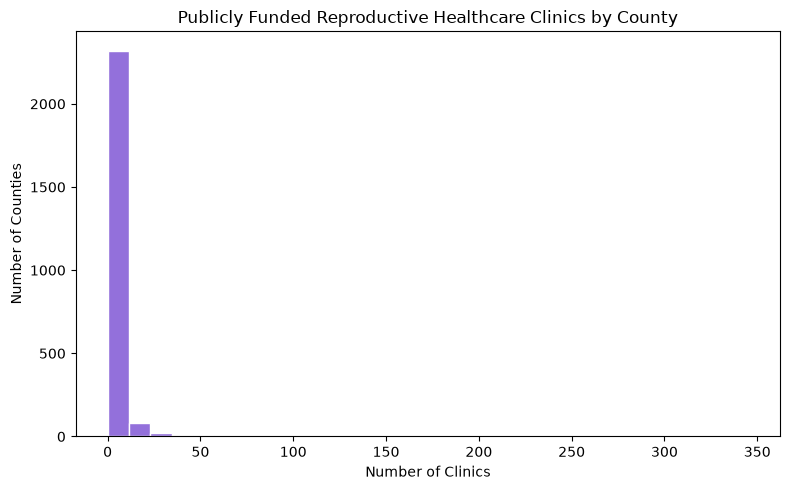

In [66]:
import matplotlib.pyplot as plt

# summary statistics
clinic_cols = [
    "Total publicly funded clinics",
    "Total Title X-funded clinics"
]

display(merged_df[clinic_cols].describe())

# comparing the clinic availability across different counties
plt.figure(figsize=(8, 5))

plt.hist(
    merged_df["Total publicly funded clinics"].dropna(),
    bins=30,
    color="mediumpurple",
    edgecolor="white"
)

plt.title("Publicly Funded Reproductive Healthcare Clinics by County")
plt.xlabel("Number of Clinics")
plt.ylabel("Number of Counties")
plt.tight_layout()
plt.show()

**Analysis about the above graph:** This graph shows us that clinic availability varies considerably between counties but it doesn't at all tell us whether income explains those differences -- so I'll be exploring that in coming steps.

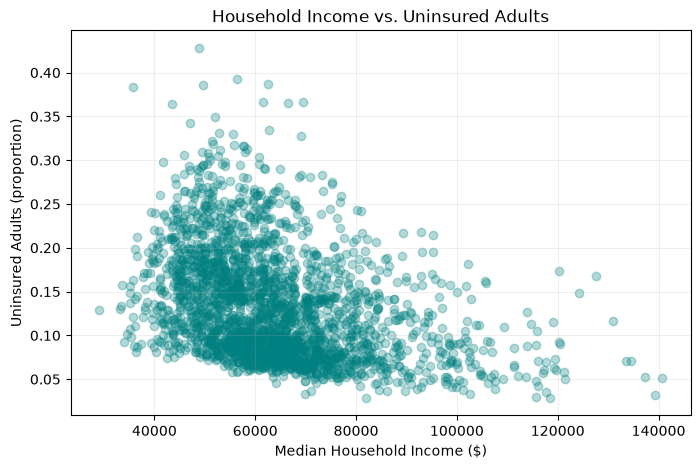

Income vs. uninsured correlation: -0.36736015274963363


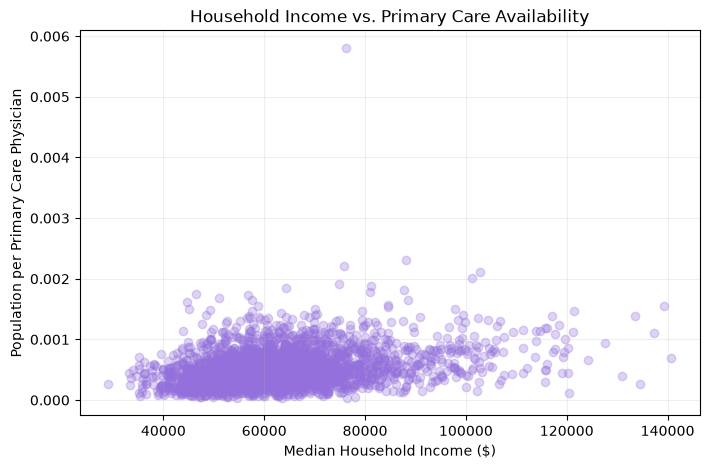

Income vs. physician ratio correlation: 0.29314029594743796


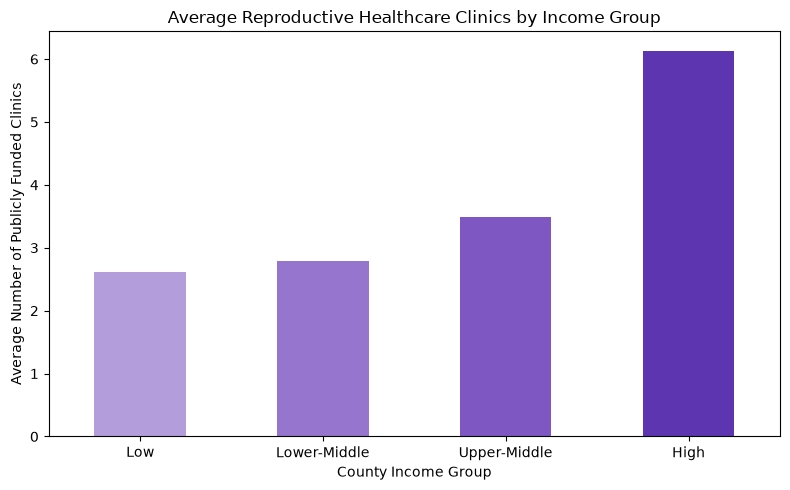

Average clinics by income group:
Income Group
Low             2.621533
Lower-Middle    2.794118
Upper-Middle    3.491830
High            6.133987
Name: Total publicly funded clinics, dtype: float64
Income vs. clinic count correlation: 0.14070134010845495


In [67]:
import pandas as pd
import matplotlib.pyplot as plt

# gathering the variables from the two merged data sets:
income = "Median Household Income raw value"
uninsured = "Uninsured Adults raw value"
physicians = "Primary Care Physicians raw value"
clinics = "Total publicly funded clinics"

# keeping complete observations for my analysis / hypothesis / research question
analysis_df = merged_df[
    [income, uninsured, physicians, clinics]
].dropna().copy()

# income vs. uninsured adults (GRAPH ONE)
plt.figure(figsize=(8, 5))
plt.scatter(analysis_df[income], analysis_df[uninsured],
            alpha=0.3, color="teal")

plt.title("Household Income vs. Uninsured Adults")
plt.xlabel("Median Household Income ($)")
plt.ylabel("Uninsured Adults (proportion)")
plt.grid(alpha=0.2)
plt.show()

print("Income vs. uninsured correlation:",
      analysis_df[income].corr(analysis_df[uninsured]))


# income vs. primary care physicians (GRAPH TWO)
plt.figure(figsize=(8, 5))
plt.scatter(analysis_df[income], analysis_df[physicians],
            alpha=0.3, color="mediumpurple")

plt.title("Household Income vs. Primary Care Availability")
plt.xlabel("Median Household Income ($)")
plt.ylabel("Population per Primary Care Physician")
plt.grid(alpha=0.2)
plt.show()

print("Income vs. physician ratio correlation:",
      analysis_df[income].corr(analysis_df[physicians]))


# income groups vs. reproductive healthcare clinics (GRAPH THREE)
analysis_df["Income Group"] = pd.qcut(
    analysis_df[income], 4,
    labels=["Low", "Lower-Middle", "Upper-Middle", "High"]
)

clinic_averages = analysis_df.groupby(
    "Income Group", observed=True
)[clinics].mean()

plt.figure(figsize=(8, 5))
clinic_averages.plot(
    kind="bar",
    color=["#b39ddb", "#9575cd", "#7e57c2", "#5e35b1"]
)

plt.title("Average Reproductive Healthcare Clinics by Income Group")
plt.xlabel("County Income Group")
plt.ylabel("Average Number of Publicly Funded Clinics")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Average clinics by income group:")
print(clinic_averages)

print("Income vs. clinic count correlation:",
      analysis_df[income].corr(analysis_df[clinics]))

#### Required: Commit your code
If working in a team we want to see commits from both team member's Github accounts over the duration of the project. Not every team ember needs to commit something ofr every problem, however make sure your commit history reflects an equal work distribution amnonmg both team members. Use a _verbose commit message_ describing your contribution for all your commits.  

<div class="alert-success">
<b>Commit your Code <i>now</i>!</b>
<br> Commit your progress to the (remote) lab repo and have a team member (who is not currently sharing the screen) check and confirm that it is there! Use a descriptive commit message, such as: "<i>descriptive commit message</i>"  
</div>

### Problem 6

**Write up!** Did you find anything interesting in [Problem 5](#Problem-5)? If you did, tell me about it. If you don't think you found anything interesting, keep looking (go back to Problem 5 or even further back to Problem 4 or 3. 

> **Hint**: Provide links to key figures in your discussion. See [this StackOverflow question](https://stackoverflow.com/questions/28080066/how-to-reference-a-ipython-notebook-cell-in-markdown) for details.

**Answer here:** (feel free to make multiple cells!)

**Graph ONE:** The first graph, depicting household income vs. uninsured adults, demonstares a moderately negative relationship meaning that as median hosuehold in come increases, the proportion of uninsured adults generally decreases. This supports the hypothesis that lower-income counties tend to have higher uninsured rates. The scatter plot also shows variable among counties with similar incomes, which would suggest that household income is NOT the only contributing explanation for insurance coverage.

**Graph TWO:** The second graph, depicting household income vs. primary care availability, demonstrates a weak positive relationship. This means that higher income counties tend to have somewhat higher values of plotted physician measure (access). The graph and data is not a population per phyisican ratio, though I would say that the positive correlation supports my hypothesis. Once again, however, this information alone is not enough to draw a firm conclusion about the relationship between household income and other healthcare accessibility observations.

**Graph THREE:** The third graph, depicting income vs. reproductive healthcare clinics, relates to my area of exploration reagrding women's health care. Here, we see that low-income counties aberage at 2.62 clinics while high-income counties average at about 6.13 clinics. The high income counties have a much greater clinics per county value, which is consistent with my expectation that higher-income counties have more reproductive healthcare facilities. However, I know to be cautious with this information as this doesn't necessarily mean that higher income residents have better access per PERSON.

**Relevance to Women's Reproductive Healthcare:**

These findings are relevant to women's reproductive health care because financial barriers and insurance coverage can influence an individual's access to necessary medical services, like those in the realm of women's health. According to the KFF (2026), about 42% of women ages 18–64 reported delaying or postponing healthcare because of cost, with uninsured women experiencing particularly high rates of delayed care. Additionally, the (although vague) coverage I looked at from research from the Guttmacher Institute (2021) also found that uninsured women were significantly less likely to receive sexual and reproductive healthcare services compared to privately insured women. This is where publicly funded clinics are especially important for lower-income and uninsured populations.

This becomes concerning for individuals with conditions such as endometriosis. The World Health Organization (2025) estimates that endometriosis affects approximately 10% of reproductive-age women worldwide, but there are SO many barriers to diagnosis and treatment that are deeply integrated into out socioeconomic system and culture.

Although my analysis does not directly measure endometriosis care, the relationships I observed between household income, insurance coverage, and publicly funded clinic availability provide a useful starting point for investigating broader socioeconomic barriers to women's reproductive healthcare and can even be beneficial with the realm of endometriosis care, though my findings were primarily focused on seeing how drastic access to reproductive health care is across varying incomes of varying counties.

#### Required: Commit your code
If working in a team we want to see commits from both team member's Github accounts over the duration of the project. Not every team ember needs to commit something ofr every problem, however make sure your commit history reflects an equal work distribution amnonmg both team members. Use a _verbose commit message_ describing your contribution for all your commits.  

<div class="alert-success">
<b>Commit your Code <i>now</i>!</b>
<br> Commit your progress to the (remote) lab repo and have a team member (who is not currently sharing the screen) check and confirm that it is there! Use a descriptive commit message, such as: "<i>descriptive commit message</i>"  
</div>

### Problem 7
One last step that we shouldn't skip is _critically reviewing_ both our data analysis approach and also the data acquisition method. 

**Write up!** Are there any **shortcommings** related to ...
* the way you used or processed this data? 
* the methods/arguments you used to form your conclusions?

**Answer here:** I removed columns with > 10% missing values and eliminated rows containing missing data because I wanted the dataset to be easier to analyze. This could have excluded counties with limited healthcare or fewer available resources which would therefore introduce bias, especially if the underserved communities were disproportionately removed (I didn't check this in my progress). 

Another limitation is that I combined datasets from different years (2024 vs 2015). Healthcare access and socioeconomic conditions may have changed significantly over the decade, meaning tha relationshiups that I identified may not accurately reflect the current, present day conditions.

**Write up!** Let's critcially review our work in the light of **ethical data science**. 
* Name at least two ethical issues related to the way you used or processed this data and/or the methods/arguments you used to form your conclusions.
* Who are the stakeholders?
* How could someone other than yourself be impacted by any ethical issues arising from your analysis/work/product?
* Propose a way to resolve the issue(s).

**Answer here:** 
1) Laws surrounding women's health care access also pose as a threat which would interfere with some of the patterns we recognized in the data set. This analyzes the relationship between money / income and access to health care, but we don't exactly know or understand the cultural and poltiical implications of access to healthcare -- which could potentially skew the patterns / representations in the data. 
2) Another ethical concern is that the available data does not fully represent women's reproductive healthcare needs. Although the dataset I provided measures publicly funded contraceptive clinics and those similiar of that nature, it does not directly measure access to gynecologists, endometriosis specialists, or the quality of reproductive healthcare services -- which makes it hard for me to deep dive into the particular endometriosis interest that I had. This is particularly important because conditions such as endometriosis are often underdiagnosed or misunderstood and using general healthcare metrics to make conclusions about reproductive healthcare could overlook the experiences of women who struggle to receive specialized treatment.

The main stakeholderss include women seeking reproductive care and those who are looking for ideal counties to live in based on their curiousity or preference of healthcare accessibility. This also impacts those experienciing endometriosis, low income and uninsured individuals, health care providers, publicly funded clinics...etc.

Ethical issues arising from this analysis could affect patients, healthcare providers, and policymakers by causing them to overlook contributing factors and metrics not present in my analysis.

**Write up!** Let's conclude with thinking about **imporvements for the future**! There are often times where the data you need doesn't exist (yet) and you need to go collect it. Based on your analysis of the data set, which features were informative and which weren't? What information that was missing from this dataset do you think would be helpful to have for a better analysis?

**Answer here:** My women's health data is from 2015 and it was hard finding data that was more relevant to this time and invovled analysis of women's health care across different counties so that I could easily draw connections between the provided data set and my new data set. I do think that we also don't understand the prices (with or without insurance) of many types of gynecological care, and having "access" to gynecological care (or being within the vicinity of a OBGYN or women's health clinic) does not necessarily mean that that individaul or group of people have access to specializaed or certain types of care. That raises the quesiton: how is this data set analyzing the difference betwene having a doctor / PCP vs. having access to specialized health care?

#### Required: Commit your code
If working in a team we want to see commits from both team member's Github accounts over the duration of the project. Not every team ember needs to commit something ofr every problem, however make sure your commit history reflects an equal work distribution amnonmg both team members. Use a _verbose commit message_ describing your contribution for all your commits.  

<div class="alert-success">
<b>Commit your Code <i>now</i>!</b>
<br> Commit your progress to the (remote) lab repo and have a team member (who is not currently sharing the screen) check and confirm that it is there! Use a descriptive commit message, such as: "<i>descriptive commit message</i>"  
</div>

### Problem 8

**Write up!** Did you use any **generative AI tools** (ChatGPT, Copilot, etc.) for this project?
* Which generative AI tools did you use?
* How did you use them? 
* How did you ensure that your project reflects your own understanding and your own contributions?
* What challenges or adjustments did you encounter when using generative AI (refining prompts, verifying accuracy, revising outputs, etc.)?

If you did not use GenAI, **reflect on your process** of doing the project work.
* What was most challenging?
* How did you overcome these challenges? 
* What was most insteresting or satisfying?
* Why did you decide to not use GenAI at all? 

**Answer here:** I used AI to gather the data set that I used for my women's health component because I wasn't exaclty sure how to extract the excel file by searching through a bunch of sites. I also used AI to help me with formatting some of my code because I wanted the most elegant looking graphs and greater clarity when cleaning my data sets.

### Problem 9

**Write up!** What was your **division of work plan**?
* Which partner did which sections?
* Was the work split evenly?

**Answer here:** I was the only contributor to the project.

#### Required: Commit your code
If working in a team we want to see commits from both team member's Github accounts over the duration of the project. Not every team ember needs to commit something ofr every problem, however make sure your commit history reflects an equal work distribution amnonmg both team members. Use a _verbose commit message_ describing your contribution for all your commits.  

<div class="alert-success">
<b>Commit your Code <i>now</i>!</b>
<br> Commit your progress to the (remote) lab repo and have a team member (who is not currently sharing the screen) check and confirm that it is there! Use a descriptive commit message, such as: "<i>descriptive commit message</i>"  
</div>

And that's it! Remember to review your work and make sure it is well presented and organized. Not everyting you coded up needs to remain in your submission. **[Does [this cell] spark joy?](https://i.kinja-img.com/gawker-media/image/upload/s--iW_3HGbT--/c_scale,dpr_2.0,f_auto,fl_progressive,q_80,w_800/oruf4oavtj5vpmvaquew.jpg)** You are always trying to communicate your findings to somebody, _maybe even yourself_. 

> **Final Grading Note/Reminder**: Your work will be graded for _creativity_, _aesthetics_, _readability_, _style_, and _cleanlines_. So, carefully document your code and use descriptive/intuitive variable names. For write-ups use consice and clear language like in a written project report. Be creative in the questions you ask/hypothesis you pose as well as in the plots you use and select visulatizations and colors that make for a plesant and intuitive viewing expereince. The goal of a good visualization is that the viewer will quickly understand your figures. 

#### Required: Final Commit
Commit your cleaned up notebook. Make sure you ahve removed any long print outs! Just commit out the print statments and rerun your nobteook. Use a _verbose commit message_ describing your contribution for all your commits.  

<div class="alert-success">
<b>Commit your Code <i>now</i>!</b>
<br> Commit your progress to the (remote) lab repo and have a team member (who is not currently sharing the screen) check and confirm that it is there! Use a descriptive commit message, such as: "<i>descriptive commit message</i>"  
</div>

### Submission instructions
* Check to make sure that your code runs without error on a fresh kernel. Within jupyter, **Kernel -> Restart & Run All**. 
* **Save your notebook!**
* Submit this Python notebook, including your answers in the code cells as homework submission. Be sure to add your partner to the submission as well.
* After submitting, navigate to the **code tab** to view your submission. Verify that all your write-ups, markdown cells, and visualizations appear correctly on Gradescope. This is the **exact** view the graders will see when grading your work, so make sure that everything looks as expected.

In [68]:
True == True

True